# 10 · Attention patterns and head routing

These diagnostics describe route use and attention weights. They do not identify causal explanations.

## Setup

Run cells in order. Default: smoke. Set `TWILIGHT_CONFIG=configs/attention_experiment.yaml` for the full preset.

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'twilight_moe').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from twilight_moe.config import load_config, run_dir
from twilight_moe.experiment import load_metrics, load_diagnostics, verify_provenance
from twilight_moe.attention import ATTENTION_NAMES
from twilight_moe.plotting import style, save_figure, COLORS
config_path = os.environ.get('TWILIGHT_CONFIG', 'configs/attention_smoke.yaml')
cfg = load_config(config_path)
if 'attention' not in cfg:
    cfg = load_config('configs/attention_smoke.yaml')
style()
print('Preset:', cfg['name'], '| seeds:', cfg['seeds'], '| epochs:', cfg['training']['epochs'])
print('Data:', cfg['data_root'])

Preset: attention_comparison_v1 | seeds: [7, 17, 27] | epochs: 40
Data: E:/HarunoKen/Twilight_MoE_Dynamics


## Load diagnostics

All examples and routes use the held-out test split after validation checkpoint selection.

In [2]:
assert verify_provenance(cfg)
seed = cfg['seeds'][0]
diagnostic = load_diagnostics(cfg,'attn_moh',seed)
display(load_metrics(cfg).query("model in ['attn_moh','attn_random','attn_both']")
        [['model','seed','head_layer0_agreement','head_layer1_agreement']].round(4))

,model,seed,head_layer0_agreement,head_layer1_agreement
8,attn_moh,7,0.3327,0.3707
9,attn_random,7,0.3339,0.4101
12,attn_both,7,0.3302,0.4641
21,attn_moh,17,0.3372,0.4197
22,attn_random,17,0.3305,0.3639
25,attn_both,17,0.3305,0.4872
34,attn_moh,27,0.3252,0.4159
35,attn_random,27,0.3303,0.4340
38,attn_both,27,0.3313,0.4280


## Routed-head utilization

Final-query routing only. Shared head 0 is always active and excluded here. Slot shares sum to one. Expert indices are arbitrary.

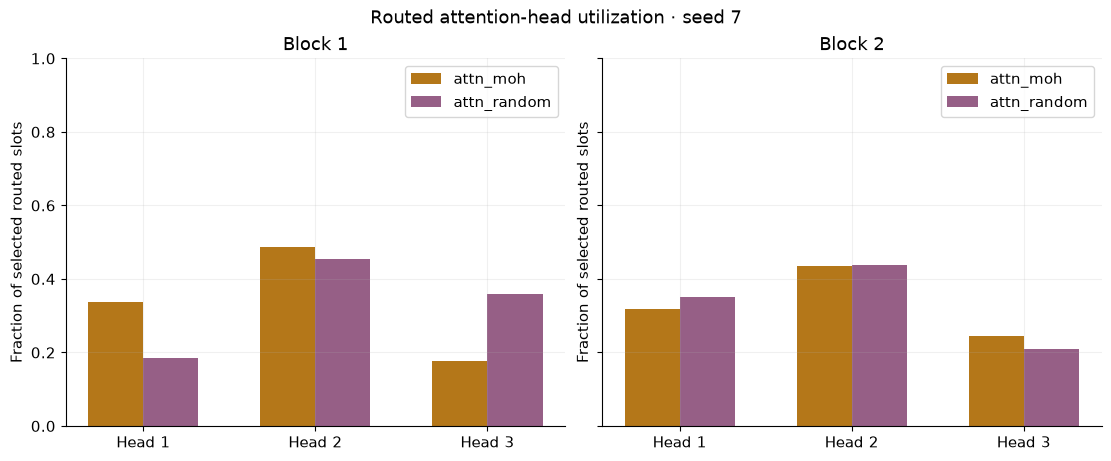

In [3]:
fig, axes = plt.subplots(1,2,figsize=(11,4.5),sharey=True)
for layer,ax in enumerate(axes):
    for j,name in enumerate(['attn_moh','attn_random']):
        values=load_diagnostics(cfg,name,seed)[f'head_layer{layer}_utilization']
        ax.bar(np.arange(3)+(j-.5)*.32,values,width=.32,color=COLORS[name],label=name)
    ax.set(xticks=range(3),xticklabels=['Head 1','Head 2','Head 3'],ylim=(0,1),
           title=f'Block {layer+1}',ylabel='Fraction of selected routed slots')
    ax.legend()
fig.suptitle(f'Routed attention-head utilization · seed {seed}')
save_figure(fig,cfg,'attention_head_utilization')
plt.show()

## Attention over history

Mean ungated attention probabilities for the final query. The graph includes all heads, even for tokens where a routed head was inactive. Position 0 is the oldest state and 7 the most recent.

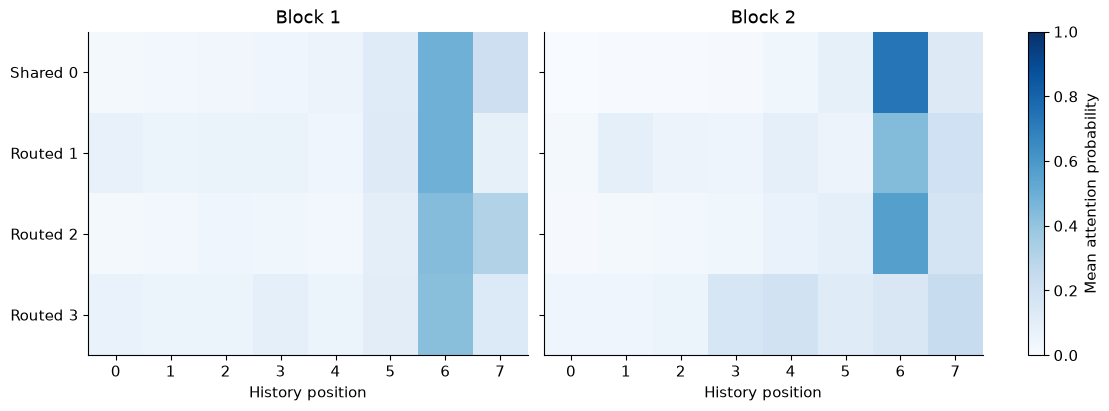

In [4]:
patterns=diagnostic['last_query_attention_mean']
fig,axes=plt.subplots(1,2,figsize=(11,4),sharey=True)
for layer,ax in enumerate(axes):
    im=ax.imshow(patterns[layer],vmin=0,vmax=1,cmap='Blues',aspect='auto')
    ax.set(xlabel='History position',yticks=range(4),yticklabels=['Shared 0','Routed 1','Routed 2','Routed 3'],
           xticks=range(cfg['data']['context']),title=f'Block {layer+1}')
    ax.grid(False)
fig.colorbar(im,ax=axes,label='Mean attention probability')
save_figure(fig,cfg,'attention_history_patterns')
plt.show()

## Regime association

Top routed head against the current transition regime, final query only. A validation-fitted permutation produces the reported test agreement. The first block gate sees only the current token embedding and position.

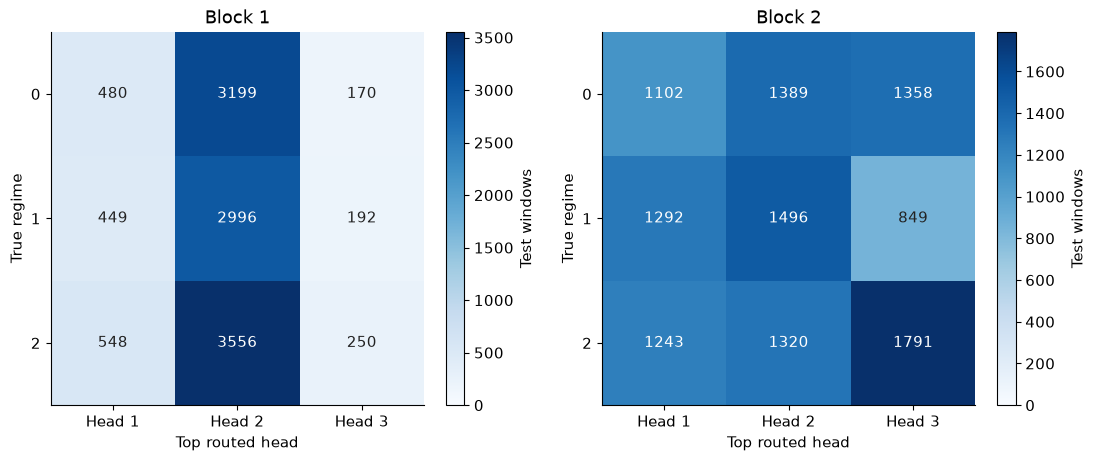

In [5]:
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
for layer,ax in enumerate(axes):
    counts=diagnostic[f'head_layer{layer}_confusion']
    im=ax.imshow(counts,cmap='Blues',vmin=0)
    for row in range(3):
        for col in range(3):
            ax.text(col,row,str(counts[row,col]),ha='center',va='center',
                    color='white' if counts[row,col]>counts.max()*.55 else '#222222')
    ax.set(xticks=range(3),xticklabels=['Head 1','Head 2','Head 3'],yticks=range(3),
           xlabel='Top routed head',ylabel='True regime',title=f'Block {layer+1}')
    ax.grid(False)
    fig.colorbar(im,ax=ax,label='Test windows')
save_figure(fig,cfg,'attention_regime_confusion')
plt.show()

## Head weights

Averaged across all tokens and test windows. Shared/routed type weights are learned. Under the paper equation, masking full-softmax weights can leave total retained mass below one.

In [6]:
display(pd.DataFrame(diagnostic['head_weight_mean'],index=['Block 1','Block 2'],
                     columns=['Shared 0','Routed 1','Routed 2','Routed 3']).round(4))

,Shared 0,Routed 1,Routed 2,Routed 3
Block 1,0.4744,0.1152,0.1762,0.1726
Block 2,0.4309,0.1516,0.1512,0.1836
